# Finding foreign objects in lentils with a normal-only Gaussian mixture

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cubert-hyperspectral/cuvis-ai/blob/main/notebooks/use_cases/lentils_gmm.ipynb)

This notebook learns what normal lentils and conveyor belt look like from unlabelled spectra,
then flags the pixels that do not fit that model. No foreign-object label is used to train the
detector; labels are only used to read the result at the end.

The method, in one line: a per-pixel validity gate, unit-length normalisation, a Gaussian
mixture over normal spectra, a threshold on the mixture's negative log-likelihood set per
recording day, and a minimum blob area tied to the size of one lentil.

```
cube -> SpectralValidity -> PerPixelUnitNorm -> GaussianMixtureClusterer
     -> negative log-likelihood -> ScoreThreshold -> MaskMinArea
```

An internal study on the same split ran a close variant of this recipe (a diagonal-covariance
mixture, the same 16 components, a conformal per-day calibration) on three recordings from this
dataset and found 44 of 68 held-out test objects with 4 of 20 normal frames firing. This
notebook builds the comparable pipeline from the nodes that ship in cuvis-ai today, fits and
calibrates on the same frames the study used, and reports where that lands next to the study's
own numbers.

The dataset is
[`cubert-gmbh/XMR_Industrial_Foreign_Object_Detection_Lentils`](https://huggingface.co/datasets/cubert-gmbh/XMR_Industrial_Foreign_Object_Detection_Lentils)
(Apache-2.0), recorded and annotated by Anish Raj and the Cubert AI team, with its whitepaper
alongside the dataset.

**Split.** Three recordings, one per acquisition day, are split by frame into three disjoint
roles: `fit` trains the mixture on normal spectra, `calib` sets each day's threshold on held-out
normal frames, and `test` is the held-out set with object labels, read once. The ids below are
the same ones an internal study on the same split used on these recordings, so the two result
rows at the end sit side by side.

> **Prerequisites**
>
> 1. A working `cuvis-ai` development environment (`uv sync` from the repo root).
> 2. Internet access on first run: the dataset (about 57 GB total) is pulled from Hugging Face
>    and cached under `~/.cache/huggingface`; this notebook reads four recordings from it.
> 3. The `cuvis-ai-dataloader` plugin (cu3s reader plus the Cuvis SDK binding) is provisioned by
>    the cell below.
> 4. Run time: streaming and scoring 172 frames with the Cuvis SDK on the CPU takes roughly
>    15 to 25 minutes end to end.

In [1]:
# Colab bootstrap: a no-op when running locally.
try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # cuvis-ai itself; the next cell provisions the plugins from the packaged manifests.
    %pip install -q "cuvis-ai>=0.22.1"
    # The C++ Cuvis SDK that reads the cu3s recordings (pip ships only its Python binding):
    # Cubert's public SDK 3.6.1 packages for the image's Ubuntu release (24.04 on Colab today,
    # 22.04 before), a ~2 GB download.
    import platform
    from pathlib import Path

    if not Path("/lib/cuvis").is_dir():  # installed already on the pass after the restart
        ubuntu = platform.freedesktop_os_release()["VERSION_ID"]
        sdk_dir = f"Cuvis 3.6.1/Ubuntu {ubuntu}-amd64-cuda12.9"
        !wget -q -O cuvis_sdk.zip https://cloud.cubert-gmbh.de/s/cuvis_sdk_release_ver_361/download
        !unzip -q -o cuvis_sdk.zip "{sdk_dir}/*.deb" && rm cuvis_sdk.zip
        !apt-get install -y -qq "./{sdk_dir}/cuviscommon_3.6.1-0.deb" "./{sdk_dir}/libcuvis_3.6.1-0.deb" | tail -n 2
    assert Path("/lib/cuvis").is_dir(), "the Cuvis SDK did not install; see the apt-get output"
    %env CUVIS=/lib/cuvis

    import torch

    if not torch.cuda.is_available():
        print("WARNING: No GPU detected. Switch via Runtime > Change runtime type > GPU.")

In [2]:
# Provision the plugins this notebook needs. Their pins live in the plugin manifests packaged with
# cuvis-ai (cuvis_ai/configs/plugins): `provision` reads them off a packaged pipeline that uses the
# same plugins, adds each manifest's own extras and the data module's, and installs only what is
# missing. After a fresh install, restart the kernel (Kernel > Restart Kernel) and rerun from the
# top. This notebook uses builtin nodes only, so any packaged pipeline works as the anchor; it is
# paired here with the `cu3s` data module this notebook reads.
from importlib.resources import files

from cuvis_ai_core.utils.provision import provision_environment, resolve_install_specs

CONFIGS = files("cuvis_ai") / "configs"
PLUGINS_DIR = CONFIGS / "plugins"
PROVISION = [  # (packaged pipeline that lists the plugin(s), data module whose extras to add)
    ("medical/blood_perfusion/ndvi.yaml", "cu3s"),
]
for pipeline_yaml, data_module in PROVISION:
    pipeline_path = CONFIGS / "pipeline" / pipeline_yaml
    if IN_COLAB:  # no uv project on Colab: pip the resolved specs straight into this kernel
        specs = resolve_install_specs(pipeline_path, [PLUGINS_DIR], data_module)
        provision_environment(specs, notebook=True, apply=True)
    else:  # the same command you would run in a terminal from the repo root
        data_arg = f"--data-module {data_module}" if data_module else ""
        !uv run provision --pipeline-path "{pipeline_path}" --plugins-dir "{PLUGINS_DIR}" {data_arg} --apply

2026-11-06 22:34:23.951 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_builtin' tag v0.22.6 → 961a1a9e from https://github.com/cubert-hyperspectral/cuvis-ai.git
2026-11-06 22:34:24.424 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_dataloader' tag v0.9.1 → 809708e6 from https://github.com/cubert-hyperspectral/cuvis-ai-dataloader.git
Using Python 3.13.7 environment at: D:\code-repos\cuvis-ai\wt-6734-lentils-gmm-notebook\.venv
Resolved 69 packages in 976ms
Audited 69 packages in 3ms


In [3]:
%matplotlib inline
from __future__ import annotations

import csv
import json
import sys
from collections.abc import Iterator
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from loguru import logger
from scipy.optimize import linear_sum_assignment

# Robust import whether Jupyter's cwd is the repo root or this notebook folder.
NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "utils.py").is_file():
    USE_CASES_DIR = NOTEBOOK_DIR
else:
    USE_CASES_DIR = NOTEBOOK_DIR / "notebooks" / "use_cases"
if str(USE_CASES_DIR) not in sys.path:
    sys.path.insert(0, str(USE_CASES_DIR))
REPO_ROOT = USE_CASES_DIR.parent.parent

logger.remove()
logger.add(sys.stderr, level="INFO")

device = (
    "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
)
logger.info(f"device: {device}")

# The Cuvis SDK's CUDA path for Reflectance has failed intermittently on this notebook's
# recordings right after a long fit; reading on the CPU avoids that failure mode.
SDK_CUDA = False

2026-11-06 22:34:28.162 | INFO     | __main__:<module>:33 - device: cuda


## 1 - Dataset and objective

`cubert-gmbh/XMR_Industrial_Foreign_Object_Detection_Lentils`: 15 merged `.cu3s` recordings of
lentils on a conveyor belt, three acquisition days, 61 bands from 430 to 910 nm, 1000 x 1080
pixels. Foreign objects are annotated as COCO polygons across 7 classes (`stem_k`, `stone`,
`alu_shard`, `blue_paper`, `white_paper`, `fly`, `rubber`); class `0` is background, which here
means normal lentils and belt.

This notebook uses four recordings: one per acquisition day for `fit` and `calib`
(2026-03-03, 2026-03-10, 2026-03-17), plus a second 2026-03-03 recording that only contributes
extra `test` frames. The 2026-03-17 recording looks different from the other two: a denser
lentil carpet and a different belt tint, with bright yellow kernels that are normal product, not
an anomaly. That shift is why the detector calibrates a threshold **per recording day** instead
of one threshold for everything.

The frame ids below are the same ones an internal study on the same split used on these
recordings, written as compact ranges so the cell stays short; `ids_from_ranges` expands a list
of `(start, stop)` pairs (stop exclusive) into the explicit ids the data module selectors need.

In [4]:
def ids_from_ranges(ranges: list[tuple[int, int]]) -> list[int]:
    """Expand a list of (start, stop) pairs (stop exclusive) into a sorted id list."""
    out: list[int] = []
    for start, stop in ranges:
        out.extend(range(start, stop))
    return sorted(out)


# One entry per recording; "fit" and "calib" are omitted for the recording that only
# contributes test frames. Recording names are the cu3s file stems, matched against the
# downloaded dataset's own universe.csv below; the ids are that file's local cu3s index.
SPLIT_RANGES: dict[str, dict[str, list[tuple[int, int]]]] = {
    "2026_03_03_13-58-04_1": {
        "fit": [(0, 16), (20, 36), (48, 56)],
        "calib": [(60, 84), (88, 92)],
        "test": [(36, 40), (84, 88)],
    },
    "2026_03_03_13-58-04_2": {
        "test": [(0, 4), (12, 16), (32, 36), (88, 92), (104, 108)],
    },
    "2026_03_10_10-17-20": {
        "fit": [(0, 12)],
        "calib": [(24, 32), (36, 40)],
        "test": [(12, 16), (20, 24), (72, 76)],
    },
    "2026_03_17_11-41-54": {
        "fit": [(0, 16)],
        "calib": [(24, 40)],
        "test": [(16, 20), (44, 48)],
    },
}

SPLIT_IDS = {
    recording: {role: ids_from_ranges(ranges) for role, ranges in roles.items()}
    for recording, roles in SPLIT_RANGES.items()
}

for role in ("fit", "calib", "test"):
    n = sum(len(roles.get(role, [])) for roles in SPLIT_IDS.values())
    print(f"{role:>5}: {n} frames")

  fit: 68 frames
calib: 56 frames
 test: 48 frames


## 2 - Get the data

`PublicDatasets.download_dataset` pulls the full snapshot once (nothing is converted; the
recordings stay as `.cu3s`). The dataset ships its own `universe.csv` (one row per frame: its
cu3s recording, its local index, its COCO annotation path); this notebook builds its own
`DataSplitConfig` selectors against it rather than using the packaged `splits.csv`, since the
roles here (`fit` / `calib` / `test`) are the internal study's own split, not the dataset's
published one.

Each role gets its own `MultiCu3sDataModule`: a selector names a recording by its row in
`universe.csv` and a list of local frame ids (`kind: file_indices`), so the three roles never
share a frame even though some of them read the same recording.

In [5]:
from cuvis_ai_core.data.public_datasets import PublicDatasets

DATA_DIR = Path("/content/data") if IN_COLAB else REPO_ROOT / "data"
PublicDatasets.download_dataset("Industrial_FOD_Lentils", download_path=str(DATA_DIR), force=False)
raw_dir = DATA_DIR / "XMR_Industrial_Foreign_Object_Detection_Lentils"
universe_csv = raw_dir / "universe.csv"

with open(universe_csv, newline="", encoding="utf-8") as fh:
    universe_rows = list(csv.DictReader(fh))
source_by_recording = {Path(r["source"]).stem: r["source"] for r in universe_rows}
annotation_by_recording = {Path(r["source"]).stem: r["annotation"] for r in universe_rows}
missing = sorted(set(SPLIT_IDS) - set(source_by_recording))
assert not missing, f"recordings not found in universe.csv: {missing}"
print(f"{len(universe_rows)} frames in the dataset's universe.csv; all 4 recordings found")

Industrial_FOD_Lentils: present at D:\code-repos\cuvis-ai\wt-6734-lentils-gmm-notebook\data\XMR_Industrial_Foreign_Object_Detection_Lentils


1136 frames in the dataset's universe.csv; all 4 recordings found


In [6]:
from cuvis_ai_dataloader.data import MultiCu3sDataModule
from cuvis_ai_schemas.training.data import DataSplitConfig


def selectors_for(role: str) -> list[dict]:
    """file_indices selectors for one role, one per recording that has ids for it."""
    return [
        {"kind": "file_indices", "source": source_by_recording[recording], "ids": ids}
        for recording, roles in SPLIT_IDS.items()
        if (ids := roles.get(role))
    ]


def datamodule_for(role: str, *, max_open_sessions: int = 3) -> MultiCu3sDataModule:
    """One MultiCu3sDataModule reading a role's frames straight from their cu3s recordings."""
    dm = MultiCu3sDataModule(
        splits=DataSplitConfig(predict=selectors_for(role)),
        universe_csv=str(universe_csv),
        processing_mode="Reflectance",
        batch_size=1,
        num_workers=0,
        max_open_sessions=max_open_sessions,
        sdk_cuda=SDK_CUDA,
    )
    dm.setup("predict")
    return dm


fit_dm = datamodule_for("fit")
calib_dm = datamodule_for("calib")
test_dm = datamodule_for("test")
print(
    f"fit: {len(fit_dm.predict_ds)} frames | calib: {len(calib_dm.predict_ds)} frames | test: {len(test_dm.predict_ds)} frames"
)

W1106 22:34:34.320000 107592 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


fit: 68 frames | calib: 56 frames | test: 48 frames


In [7]:
def recording_of(source: str) -> str:
    """cu3s file stem from a universe.csv source path or an annotation_json batch field."""
    return Path(source).stem


def day_of(recording: str) -> str:
    """Acquisition day of a recording name, e.g. '2026_03_03' from '2026_03_03_13-58-04_1'."""
    return recording[:10]


def iter_role(dm: MultiCu3sDataModule) -> Iterator[tuple[str, int, torch.Tensor]]:
    """Yield (recording, local_index, cube[H,W,C] float32 cpu) for every frame a data module reads."""
    for batch in dm.predict_dataloader():
        cube = batch["cube"][0].to(torch.float32)
        idx = int(batch["mesu_index"][0].item())
        rec = recording_of(batch["annotation_json"][0])
        yield rec, idx, cube

## 3 - The pipeline, node by node

- **`SpectralValidity`** flags non-finite, too-faint, and out-of-ROI pixels per frame and marks
  a frame `frame_status != 0` when too little of it is valid. The settings below are the
  internal study's own: a norm floor of 50, no saturation cut, at least half the frame valid,
  checked against the dataset's 61-band grid (430 to 910 nm, 8 nm steps, 1 nm tolerance) on the
  1000 x 1080 reference frame.
- **`PerPixelUnitNorm`** mean-centers each pixel's spectrum across bands and scales it to unit
  length. The study instead divided by the norm with no centering step; the library has no
  plain L2-only node, so this notebook uses `PerPixelUnitNorm` as it ships.
- **`GaussianMixtureClusterer`** fits a 16-component Gaussian mixture over the unit-normalised
  fit-split spectra and scores every pixel with the mixture's log-likelihood. The library node
  is full-covariance only; the study used a diagonal covariance. A full-covariance fit is a
  strictly more expressive model of the same normal spectra.
- **`ScoreThreshold`** and **`MaskMinArea`** turn the per-pixel score into a mask. The node
  gives log-likelihood (higher = more normal); the study's score, and the one calibrated in
  section 5, is its negation, `-log p(x)` (higher = more anomalous). Section 6 feeds
  `ScoreThreshold` the raw log-likelihood with `keep="below"`, so `log p(x) <= -t` marks exactly
  the pixels the study's `-log p(x) > t` would mark anomalous, for calibrated threshold `t`.
  `MaskMinArea(min_area=453, cell=1)` keeps 8-connected blobs of at least 453 pixels (about half
  a lentil at this resolution), matching the study's area rule.

No library node yet computes a per-recording-day conformal threshold from calibration frames, or
matches predicted blobs to ground-truth objects; both are short cells in section 5 and 6, reusing
the same evaluation functions a byte-for-byte check against the study's own saved score maps
already verified.

In [8]:
from cuvis_ai.node.clustering.gmm import GaussianMixtureClusterer
from cuvis_ai.node.deciders.binary_decider import ScoreThreshold
from cuvis_ai.node.mask_ops import MaskMinArea
from cuvis_ai.node.normalization import PerPixelUnitNorm
from cuvis_ai.node.preprocessors import SpectralValidity

N_BANDS = 61
WAVELENGTH_GRID = [430.0 + 8.0 * i for i in range(N_BANDS)]  # 430..910 nm, 8 nm steps

validity = SpectralValidity(
    n_features=N_BANDS,
    expected_wavelengths=WAVELENGTH_GRID,
    wavelength_tol_nm=1.0,
    norm_floor=50.0,
    saturation_value=None,
    roi_reference_hw=[1000, 1080],
    min_valid_fraction=0.5,
    name="validity",
)
unit_normalize = PerPixelUnitNorm(eps=1e-8, name="unit_normalize")
gmm = GaussianMixtureClusterer(
    n_components=16,
    covariance_type="full",
    reg_covar=1e-6,  # placeholder; recomputed from the fit pixels in section 4 before fitting
    max_iter=200,
    n_init=3,
    random_state=0,
    max_fit_pixels=300_000,
    fit_seed=0,
    name="gmm",
)
threshold_node = ScoreThreshold(threshold=1.0, keep="below", name="threshold")  # placeholder
area_filter = MaskMinArea(min_area=453, cell=1, name="area_filter")

In [9]:
from cuvis_ai_core.pipeline.pipeline import CuvisPipeline

pipeline = CuvisPipeline("lentils_gmm")
pipeline.connect(unit_normalize.outputs.normalized, gmm.inputs.cube)
pipeline

lentils_gmm:
PerPixelUnitNorm()
GaussianMixtureClusterer()
Use `pipeline.visualize()` for Graphviz/Mermaid output.

## 4 - Fit on the FIT split

`GaussianMixtureClusterer.statistical_initialization` consumes a stream of `{"cube": ...}`
batches and fits scikit-learn's `GaussianMixture` once, drawing up to `max_fit_pixels` pixels
uniformly at random from what it is handed. Concatenating all 68 FIT frames at full resolution
before that subsample would need about 18 GB of pixel data, more than fits comfortably
alongside everything else running on this machine; each frame is pre-subsampled to a per-frame
cap before it reaches the node, so the concatenation itself never gets that large, and the
node's own seeded `max_fit_pixels` subsample still decides which pixels it fits on.

`reg_covar` is set from the fit data itself: one hundredth of the median per-band variance of
the normalised fit pixels, the same rule the study used (translated to this node's single
`reg_covar` scalar, since the library mixture is full-covariance rather than diagonal).

In [10]:
N_FIT_FRAMES = sum(len(roles.get("fit", [])) for roles in SPLIT_IDS.values())
PER_FRAME_FIT_CAP = max(1, int(gmm.max_fit_pixels * 1.5 // N_FIT_FRAMES))
print(
    f"{N_FIT_FRAMES} fit frames; per-frame cap {PER_FRAME_FIT_CAP} pixels before the node's own subsample"
)


def capped_fit_pixels(frame_index: int, cube_hwc: torch.Tensor) -> torch.Tensor:
    """One frame's unit-normalised pixels, subsampled to PER_FRAME_FIT_CAP if larger."""
    normed = unit_normalize.forward(data=cube_hwc.unsqueeze(0))["normalized"]
    flat = normed.reshape(-1, N_BANDS)
    if flat.shape[0] > PER_FRAME_FIT_CAP:
        gen = torch.Generator(device="cpu").manual_seed(gmm.fit_seed * 100_003 + frame_index)
        pick = torch.randperm(flat.shape[0], generator=gen)[:PER_FRAME_FIT_CAP]
        flat = flat[pick]
    return flat


fit_chunks = [capped_fit_pixels(i, cube) for i, (_rec, _idx, cube) in enumerate(iter_role(fit_dm))]
fit_dm.predict_ds.close()  # every open recording holds SDK memory; the FIT frames are read once
all_fit_pixels = torch.cat(fit_chunks, dim=0)
if all_fit_pixels.shape[0] > gmm.max_fit_pixels:
    gen = torch.Generator(device="cpu").manual_seed(gmm.fit_seed)
    pick = torch.randperm(all_fit_pixels.shape[0], generator=gen)[: gmm.max_fit_pixels]
    reg_covar_sample = all_fit_pixels[pick]
else:
    reg_covar_sample = all_fit_pixels
median_band_variance = float(reg_covar_sample.var(dim=0, unbiased=True).median().item())
gmm.reg_covar = 0.01 * median_band_variance
gmm.hparams["reg_covar"] = gmm.reg_covar  # keep the saved-pipeline snapshot in sync with the fit
print(f"median per-band variance: {median_band_variance:.3e} | reg_covar: {gmm.reg_covar:.3e}")

68 fit frames; per-frame cap 6617 pixels before the node's own subsample


median per-band variance: 7.299e-04 | reg_covar: 7.299e-06


In [11]:
# The per-frame-capped chunks already collected above are fed straight to the node: reading the
# 68 FIT frames a second time would cost several more minutes for no new information, since
# capped_fit_pixels is a deterministic, seeded subsample.
gmm.statistical_initialization([{"cube": chunk.reshape(1, -1, 1, N_BANDS)} for chunk in fit_chunks])
print(f"fitted | components: {gmm.weights.shape[0]} | mean weight: {gmm.weights.mean():.4f}")

fitted | components: 16 | mean weight: 0.0625


## 5 - Calibrate a threshold per recording day

No library node yet computes a per-recording-day conformal threshold or matches predicted blobs
to ground-truth objects by Hungarian assignment at a minimum IoU, so both are plain functions
below, checked byte-for-byte against the internal study's own saved score maps before this
notebook was written.

`frame_critical_threshold` is the smallest score threshold at which a calibration frame (known
to be free of foreign objects) would still produce no qualifying blob under `area_filter`'s
rule: the largest value a detector could use on that frame without firing. `conformal_threshold`
takes the k-th smallest critical value across a day's calibration frames
(`k = ceil((n + 1) * (1 - alpha))`), the usual split-conformal guarantee for a frame false-alarm
rate of at most `alpha`; with as few as 12 calibration frames on one day, the attainable rate is
coarse (`k` can exceed `n`, in which case the largest critical value is used and the nominal
rate is not quite reached).

In [12]:
def label_components(mask_2d: np.ndarray, connectivity: int = 8) -> tuple[np.ndarray, int]:
    """8-connected (or 4-connected) components of a boolean mask: (labels, count)."""
    binary = (np.asarray(mask_2d) != 0).astype(np.uint8)
    if not binary.any():
        return np.zeros_like(binary, dtype=np.int32), 0
    n, labels = cv2.connectedComponents(binary, connectivity=connectivity)
    return labels.astype(np.int32, copy=False), n - 1


def _has_qualifying_component(
    scores: np.ndarray, valid: np.ndarray, threshold: float, min_area_px: int, connectivity: int
) -> bool:
    candidate = valid & (scores > threshold)
    if not candidate.any():
        return False
    labels, n = label_components(candidate, connectivity)
    if n == 0:
        return False
    areas = np.bincount(labels.ravel())[1:]
    return bool((areas >= min_area_px).any())


def frame_critical_threshold(
    score_2d: np.ndarray, valid_2d: np.ndarray, min_area_px: int, connectivity: int = 8
) -> float:
    """Smallest threshold t such that no component of valid & (score > t) reaches min_area_px."""
    valid = valid_2d.astype(bool)
    scores = np.asarray(score_2d, dtype=np.float64)
    valid_scores = scores[valid]
    if valid_scores.size == 0:
        return float("inf")
    finite_scores = valid_scores[np.isfinite(valid_scores)]
    if finite_scores.size == 0:
        return float("inf")
    uniq = np.unique(finite_scores)

    def has_detection(t: float) -> bool:
        return _has_qualifying_component(scores, valid, t, min_area_px, connectivity)

    if not has_detection(uniq[0] - 1.0):
        return float("-inf")
    if has_detection(uniq[-1]):
        return float(uniq[-1])
    lo, hi = -1, uniq.size - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if has_detection(uniq[mid]):
            lo = mid
        else:
            hi = mid
    return float(uniq[hi])


def conformal_threshold(critical: np.ndarray, alpha: float) -> tuple[float, int, bool]:
    """k-th smallest critical value, k = ceil((n+1) * (1 - alpha)); achievable=False if k > n."""
    critical = np.asarray(critical, dtype=np.float64)
    n = critical.shape[0]
    k = int(np.ceil((n + 1) * (1.0 - alpha)))
    sorted_critical = np.sort(critical)
    if k > n:
        return float(sorted_critical[-1]), k, False
    return float(sorted_critical[k - 1]), k, True

In [13]:
def score_frame(cube_hwc: torch.Tensor) -> tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    """(-log-likelihood, raw log-likelihood, validity, frame_status) for one frame, [H, W] numpy.

    The calibration below works in -log-likelihood (higher = more anomalous, the study's own
    score); the raw log-likelihood is kept alongside because ScoreThreshold takes its decision
    on that port directly in section 6 (see the note there on the sign and the threshold).
    """
    cube_bhwc = cube_hwc.unsqueeze(0)
    v_out = validity.forward(cube=cube_bhwc)
    normed = unit_normalize.forward(data=cube_bhwc)["normalized"]
    with torch.no_grad():
        log_lik = gmm.forward(cube=normed)["scores"]
    log_lik_2d = log_lik[0, :, :, 0].numpy().astype(np.float64)
    score = -log_lik_2d
    valid = v_out["valid_mask"][0, :, :, 0].numpy()
    frame_status = int(v_out["frame_status"][0].item())
    return score, log_lik_2d, valid, frame_status


MIN_AREA = 453  # about half a lentil at 1000 x 1080, the study's own area rule
CONNECTIVITY = 8
TARGET_FA = 0.05  # target per-day frame false-alarm rate

critical_by_day: dict[str, list[float]] = {}
for _rec, _idx, cube in iter_role(calib_dm):
    score, _log_lik, valid, frame_status = score_frame(cube)
    if frame_status != 0:
        continue
    day = day_of(_rec)
    critical_by_day.setdefault(day, []).append(
        frame_critical_threshold(score, valid, MIN_AREA, CONNECTIVITY)
    )
calib_dm.predict_ds.close()

thresholds: dict[str, float] = {}
for day, crits in sorted(critical_by_day.items()):
    thr, k, achievable = conformal_threshold(np.array(crits), TARGET_FA)
    thresholds[day] = thr
    note = "" if achievable else " (not achievable at this n; using the largest critical value)"
    print(f"{day}: n={len(crits)} k={k} threshold={thr:.2f}{note}")

2026_03_03: n=28 k=28 threshold=-244.44
2026_03_10: n=12 k=13 threshold=-242.29 (not achievable at this n; using the largest critical value)
2026_03_17: n=16 k=17 threshold=-231.32 (not achievable at this n; using the largest critical value)


## 6 - Test on the held-out split

The per-day threshold goes through `ScoreThreshold`'s `threshold` input port rather than the
constructor hyperparameter, since it differs by recording day. `ScoreThreshold` keeps the pixels
at or below its threshold; feeding it the mixture's raw log-likelihood directly (not negated) and
asking it to keep "below" marks exactly the low-likelihood, anomalous pixels: `log p(x) <=
-t` is the same test as `-log p(x) > t`, the calibrated score and threshold `t` from section 5.
`ScoreThreshold` also requires a non-negative threshold; `-t` is positive for all three days
here, since each `t` came out negative, so no extra offset is needed.

The study's own comparison counts a calibration-frame tie (`score == threshold`) as firing,
which is a `>` test on the negated score, i.e. `>=` on `-t` in log-likelihood terms; `ScoreThreshold`
is strict the other way (`<=` keeps). Nudging `-t` one float32 step towards negative infinity
with `np.nextafter` turns the node's strict `<=` into the study's non-strict `>=` at that one
value, with no effect anywhere else.

Object-level recall comes from one-to-one Hungarian matching between predicted blobs and
ground-truth polygons on IoU, an object counting as found at IoU >= 0.1 as the study defined it;
pixel average precision pools every valid test pixel's score against its ground-truth label.

In [14]:
def load_coco(json_path: Path) -> tuple[dict[int, dict], dict[int, list[dict]]]:
    coco = json.loads(json_path.read_text(encoding="utf-8"))
    images = {int(im["id"]): im for im in coco["images"]}
    anns: dict[int, list[dict]] = {}
    for ann in coco["annotations"]:
        anns.setdefault(int(ann["image_id"]), []).append(ann)
    return images, anns


def rasterize(segmentation: list, height: int = 1000, width: int = 1080) -> np.ndarray:
    canvas = np.zeros((height, width), np.uint8)
    for poly in segmentation:
        pts = np.asarray(poly, dtype=np.float64).reshape(-1, 2)
        cv2.fillPoly(canvas, [np.round(pts).astype(np.int32)], 1)
    return canvas.astype(bool)


def frame_objects(images, anns, frame_id: int) -> tuple[bool, list[np.ndarray]]:
    """(is_anomalous, object masks) for one local frame id."""
    frame_anns = anns.get(frame_id, [])
    masks = [rasterize(a.get("segmentation") or []) for a in frame_anns]
    return bool(frame_anns), masks


def match_objects_hungarian(
    gt: list[np.ndarray], pred: list[np.ndarray], iou_min: float = 0.1
) -> int:
    """Count of ground-truth objects matched one-to-one to a predicted blob at IoU >= iou_min."""
    if not gt or not pred:
        return 0
    iou = np.zeros((len(gt), len(pred)))
    for i, g in enumerate(gt):
        for j, p in enumerate(pred):
            inter = np.logical_and(g, p).sum()
            if inter:
                iou[i, j] = inter / np.logical_or(g, p).sum()
    cost = np.where(iou >= iou_min, 1.0 - iou, 1e6)
    rows, cols = linear_sum_assignment(cost)
    return sum(1 for r, c in zip(rows, cols, strict=True) if cost[r, c] < 1e6)


def components_from_mask(mask_2d: np.ndarray, connectivity: int = 8) -> list[np.ndarray]:
    labels, n = label_components(mask_2d, connectivity)
    return [labels == i for i in range(1, n + 1)]

In [15]:
from sklearn.metrics import average_precision_score

coco_cache: dict[str, tuple[dict, dict]] = {}


def coco_for(recording: str) -> tuple[dict, dict]:
    if recording not in coco_cache:
        ann_path = raw_dir / annotation_by_recording[recording]
        coco_cache[recording] = load_coco(ann_path)
    return coco_cache[recording]


overall = {
    "n_gt_objects": 0,
    "n_matched": 0,
    "n_anomalous_frames": 0,
    "n_normal_frames": 0,
    "n_normal_firing": 0,
}
by_day: dict[str, dict] = {}
scores_for_ap: list[np.ndarray] = []
labels_for_ap: list[np.ndarray] = []
preview_rows: list[dict] = []

for rec, idx, cube in iter_role(test_dm):
    day = day_of(rec)
    day_stats = by_day.setdefault(
        day,
        {
            "n_gt_objects": 0,
            "n_matched": 0,
            "n_anomalous_frames": 0,
            "n_normal_frames": 0,
            "n_normal_firing": 0,
        },
    )
    score, log_lik, valid, frame_status = score_frame(cube)
    images, anns = coco_for(rec)
    is_anomalous, gt_objects = frame_objects(images, anns, idx)

    if frame_status == 0:
        t = thresholds[day]  # calibrated on -log-likelihood: anomalous means score > t
        # log p(x) <= -t, nudged one float32 step towards -inf for the study's non-strict tie;
        # the node's scores and threshold are float32, so the step has to be taken in float32 or
        # it rounds straight back to the unnudged value once cast.
        neg_t = float(np.nextafter(np.float32(-t), np.float32(-np.inf)))
        log_lik_t = torch.from_numpy(log_lik).to(torch.float32)[None, :, :, None]
        threshold_t = torch.tensor([neg_t], dtype=torch.float32)
        decisions = threshold_node.forward(scores=log_lik_t, threshold=threshold_t)["decisions"]
        decisions = area_filter.forward(decisions=decisions)["decisions"]
        pred_mask = decisions[0, :, :, 0].numpy() & valid
    else:
        pred_mask = np.zeros_like(valid, dtype=bool)

    pred_blobs = components_from_mask(pred_mask, CONNECTIVITY)
    n_matched = match_objects_hungarian(gt_objects, pred_blobs, iou_min=0.1) if is_anomalous else 0
    has_anomaly = bool(pred_blobs)

    for stats in (overall, day_stats):
        if is_anomalous:
            stats["n_gt_objects"] += len(gt_objects)
            stats["n_matched"] += n_matched
            stats["n_anomalous_frames"] += 1
        else:
            stats["n_normal_frames"] += 1
            stats["n_normal_firing"] += int(has_anomaly)

    if frame_status == 0:
        gt_mask = np.zeros_like(valid, dtype=bool)
        for obj in gt_objects:
            gt_mask |= obj
        scores_for_ap.append(score[valid])
        labels_for_ap.append(gt_mask[valid])

    preview_rows.append(
        {
            "recording": rec,
            "frame_id": idx,
            "day": day,
            "cube": cube,
            "score": score,
            "valid": valid,
            "pred_mask": pred_mask,
            "gt_objects": gt_objects,
            "is_anomalous": is_anomalous,
        }
    )

test_dm.predict_ds.close()

all_scores = np.concatenate(scores_for_ap)
all_labels = np.concatenate(labels_for_ap)
pixel_ap = float(average_precision_score(all_labels, all_scores))

print(f"test objects found: {overall['n_matched']} / {overall['n_gt_objects']}")
print(f"normal frames firing: {overall['n_normal_firing']} / {overall['n_normal_frames']}")
print(f"pixel AP: {pixel_ap:.3f}")
for day, s in sorted(by_day.items()):
    print(
        f"  {day}: objects {s['n_matched']}/{s['n_gt_objects']} "
        f"| normal firing {s['n_normal_firing']}/{s['n_normal_frames']}"
    )

2026-11-06 22:40:41.019 | WARNING  | cuvis_ai_dataloader.data.readers.cu3s_pool:_note_eviction:410 - cu3s reader cache is full (3 open sessions): closing 2026_03_03_13-58-04_1.cu3s to open 2026_03_17_11-41-54.cu3s. Every such eviction rebuilds a ProcessingContext (about 13 s). Raise max_open_sessions, or set source_coherent_batches=True so a batch stays inside one recording.


test objects found: 41 / 68
normal frames firing: 3 / 20
pixel AP: 0.515
  2026_03_03: objects 40/48 | normal firing 1/8
  2026_03_10: objects 0/8 | normal firing 2/8
  2026_03_17: objects 1/12 | normal firing 0/4


### 6.1 - Against the internal study

Both rows run the same split (fit 68, calibration 56, test 48) and the same area rule. The
difference is the model and the normalisation this notebook's library nodes use in place of the
study's own: a full-covariance mixture instead of diagonal, and a mean-centred unit norm instead
of a plain one. The comparison is therefore a test of what that library-node substitution costs,
not an attempt to match the study bit for bit.

Two further runs on the same split isolate each substitution on its own. Swapping only the
normalisation (the full-covariance mixture with a plain, uncentred unit norm instead of
`PerPixelUnitNorm`) measured 39 of 68 objects with 2 of 20 normal frames firing, pixel AP 0.426.
Running the study's own diagonal-covariance mixture through this same data path (plain unit norm,
no centring) measured 42 of 68 objects with 3 of 20 normal frames firing, pixel AP 0.423, close to
the study's own 44/68 and 4/20.

In [16]:
rows = [
    ("internal study (diagonal mixture, plain unit norm)", "44 / 68", "4 / 20", "0.321"),
    (
        "this notebook (GaussianMixtureClusterer, PerPixelUnitNorm)",
        f"{overall['n_matched']} / {overall['n_gt_objects']}",
        f"{overall['n_normal_firing']} / {overall['n_normal_frames']}",
        f"{pixel_ap:.3f}",
    ),
]
print(f"{'configuration':<58s} {'objects found':>14s} {'normal firing':>14s} {'pixel AP':>9s}")
for configuration, objects_found, normals_firing, ap in rows:
    print(f"{configuration:<58s} {objects_found:>14s} {normals_firing:>14s} {ap:>9s}")

print()
print("per-day breakdown (study / this notebook)")
study_by_day = {
    "2026_03_03": ("40/48", "2/8"),
    "2026_03_10": ("0/8", "0/8"),
    "2026_03_17": ("2/4", "0/12"),
}
for day in sorted(by_day):
    s_obj, s_norm = study_by_day.get(day, ("-", "-"))
    s = by_day[day]
    print(
        f"  {day}: study {s_obj} objects, {s_norm} normal firing | "
        f"notebook {s['n_matched']}/{s['n_gt_objects']} objects, "
        f"{s['n_normal_firing']}/{s['n_normal_frames']} normal firing"
    )

configuration                                               objects found  normal firing  pixel AP
internal study (diagonal mixture, plain unit norm)                44 / 68         4 / 20     0.321
this notebook (GaussianMixtureClusterer, PerPixelUnitNorm)        41 / 68         3 / 20     0.515

per-day breakdown (study / this notebook)
  2026_03_03: study 40/48 objects, 2/8 normal firing | notebook 40/48 objects, 1/8 normal firing
  2026_03_10: study 0/8 objects, 0/8 normal firing | notebook 0/8 objects, 2/8 normal firing
  2026_03_17: study 2/4 objects, 0/12 normal firing | notebook 1/12 objects, 0/4 normal firing


## 7 - A look at the predictions

One test frame per day, each rendered three ways: a false-colour view from a
`FixedWavelengthSelector` (650/550/450 nm), the negative log-likelihood map, and the final mask
against the ground-truth object outlines (green). Matplotlib here only renders node outputs,
never recomputes them.

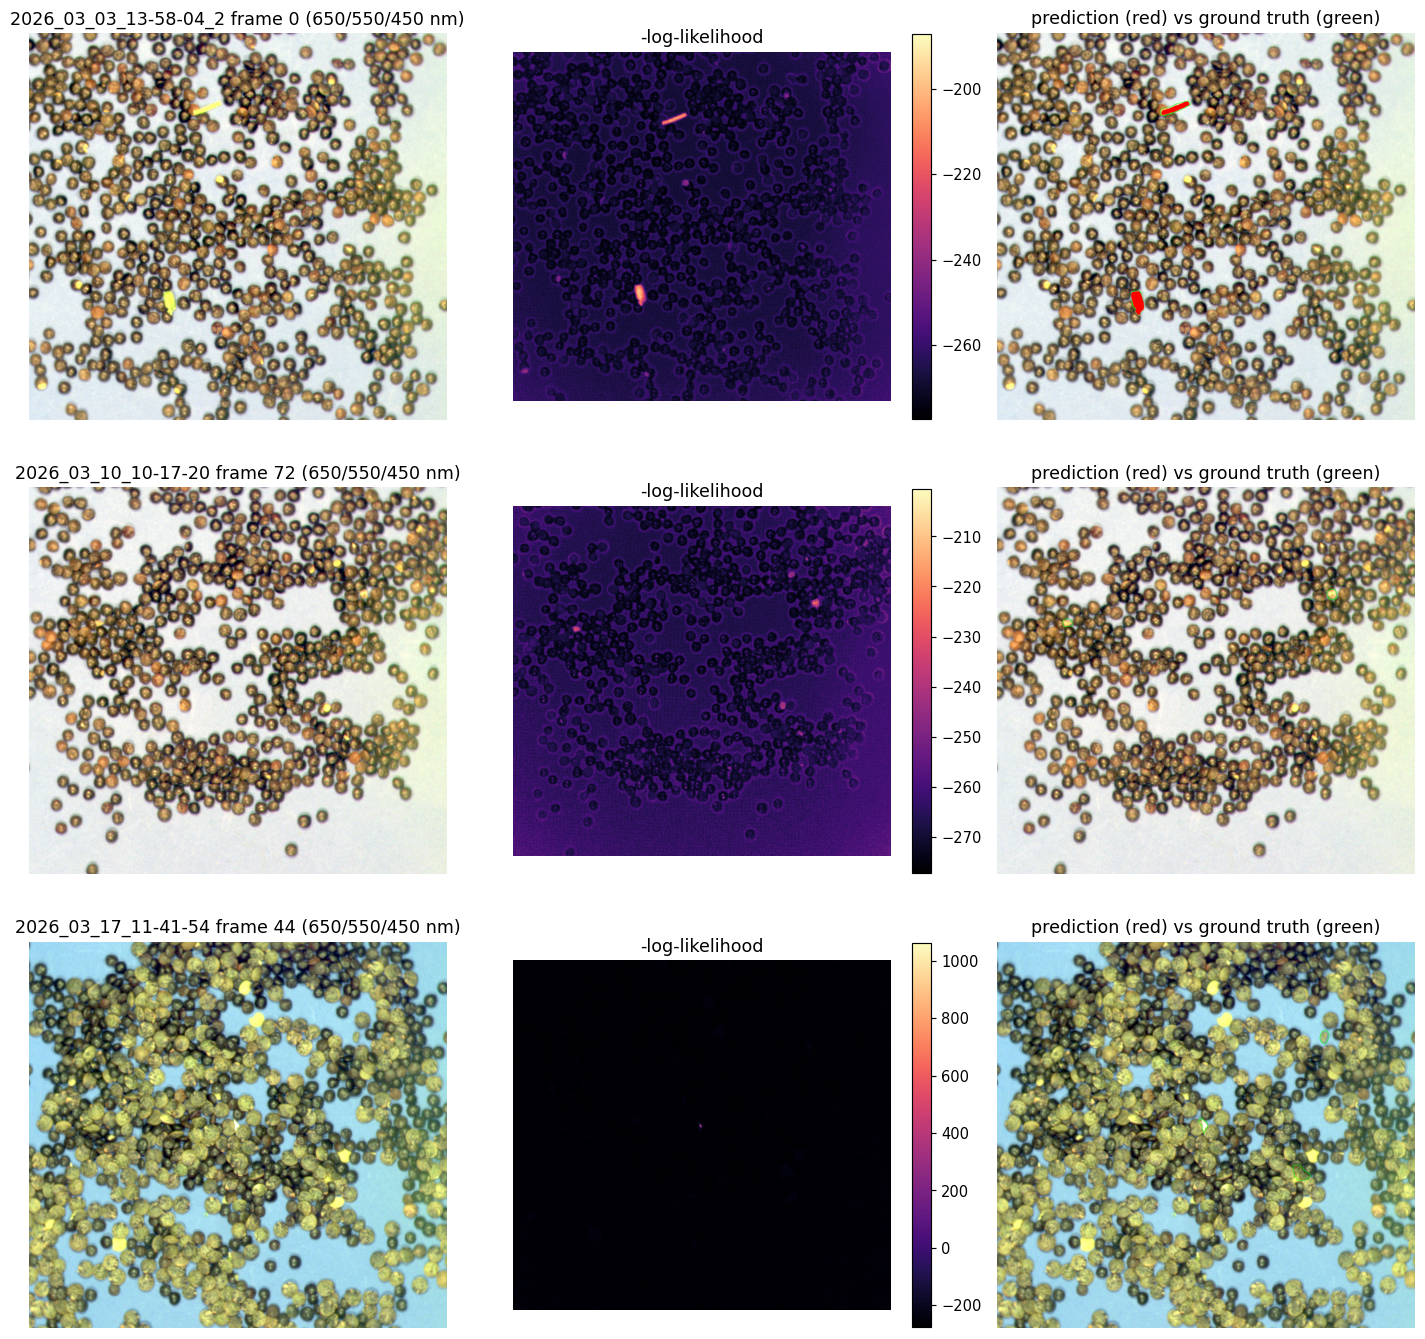

In [17]:
from cuvis_ai.node.channel_selector import FixedWavelengthSelector

false_colour = FixedWavelengthSelector(
    target_wavelengths=(650.0, 550.0, 450.0), name="false_colour"
)

shown_days: set[str] = set()
rows_to_plot = []
for row in preview_rows:
    if row["day"] not in shown_days and row["is_anomalous"]:
        rows_to_plot.append(row)
        shown_days.add(row["day"])
    if len(rows_to_plot) >= 3:
        break

fig, axes = plt.subplots(len(rows_to_plot), 3, figsize=(13.5, 4.4 * len(rows_to_plot)), dpi=105)
if len(rows_to_plot) == 1:
    axes = axes[None, :]
for i, row in enumerate(rows_to_plot):
    rgb = false_colour.forward(cube=row["cube"].unsqueeze(0), wavelengths=WAVELENGTH_GRID)[
        "rgb_image"
    ][0].numpy()
    axes[i, 0].imshow(np.clip(rgb, 0, 1))
    axes[i, 0].set_title(f"{row['recording']} frame {row['frame_id']} (650/550/450 nm)")

    score_vis = np.where(row["valid"], row["score"], np.nan)
    im = axes[i, 1].imshow(score_vis, cmap="magma")
    axes[i, 1].set_title("-log-likelihood")
    fig.colorbar(im, ax=axes[i, 1], fraction=0.046)

    overlay = np.clip(rgb, 0, 1).copy()
    gt_mask = np.zeros_like(row["valid"], dtype=bool)
    for obj in row["gt_objects"]:
        gt_mask |= obj
    boundary_gt = cv2.dilate(gt_mask.astype(np.uint8), np.ones((3, 3), np.uint8)) - gt_mask.astype(
        np.uint8
    )
    overlay[boundary_gt.astype(bool)] = [0, 1, 0]
    overlay[row["pred_mask"]] = [1, 0, 0]
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("prediction (red) vs ground truth (green)")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 8 - Save the pipeline

The pipeline graph (`PerPixelUnitNorm -> GaussianMixtureClusterer`) is saved as YAML plus the
fitted mixture weights with the pipeline's own `save_to_file`. `SpectralValidity`,
`ScoreThreshold`, and `MaskMinArea` stay out of the saved graph: the validity gate and the area
filter are stateless and the threshold is day-specific rather than a fixed hyperparameter, so
the per-day thresholds are saved alongside as a small JSON instead.

In [18]:
import yaml

output_dir = USE_CASES_DIR / "outputs" / "lentils_gmm"
output_dir.mkdir(parents=True, exist_ok=True)

pipeline_path = output_dir / "lentils_gmm_pipeline.yaml"
pipeline.save_to_file(str(pipeline_path))

# Every node here is a cuvis-ai builtin, built in this notebook rather than loaded from a YAML,
# so the pipeline object never saw a `plugins:` list to carry over. Set it directly so the saved
# file is loadable with `restore-pipeline` on its own.
with open(pipeline_path, encoding="utf-8") as fh:
    pipeline_doc = yaml.safe_load(fh)
pipeline_doc["plugins"] = ["cuvis_ai_builtin"]
with open(pipeline_path, "w", encoding="utf-8") as fh:
    yaml.safe_dump(pipeline_doc, fh, sort_keys=False)

thresholds_path = output_dir / "lentils_gmm_thresholds.json"
with open(thresholds_path, "w", encoding="utf-8") as fh:
    json.dump(
        {
            "min_area": MIN_AREA,
            "connectivity": CONNECTIVITY,
            "reg_covar": gmm.reg_covar,
            "thresholds": thresholds,
        },
        fh,
        indent=2,
    )

print(f"pipeline: {pipeline_path}")
print(f"thresholds: {thresholds_path}")

2026-11-06 22:41:18.435 | INFO     | cuvis_ai_core.pipeline.pipeline:save_to_file:640 - Pipeline saved: Config=D:\code-repos\cuvis-ai\wt-6734-lentils-gmm-notebook\notebooks\use_cases\outputs\lentils_gmm\lentils_gmm_pipeline.yaml, Weights=D:\code-repos\cuvis-ai\wt-6734-lentils-gmm-notebook\notebooks\use_cases\outputs\lentils_gmm\lentils_gmm_pipeline.pt


pipeline: D:\code-repos\cuvis-ai\wt-6734-lentils-gmm-notebook\notebooks\use_cases\outputs\lentils_gmm\lentils_gmm_pipeline.yaml
thresholds: D:\code-repos\cuvis-ai\wt-6734-lentils-gmm-notebook\notebooks\use_cases\outputs\lentils_gmm\lentils_gmm_thresholds.json


## 9 - Takeaways

The per-day threshold is not an afterthought bolted on at evaluation time; it is as much a part
of the fitted model as the mixture parameters. A single threshold calibrated across all three
days would have to sit high enough to stay quiet on whichever day scores highest, which starves
detection on the other two. Calibrating per day from a handful of that day's own confirmed-normal
frames lets a new acquisition session reach its target false-alarm rate with no retraining, as
long as a few normal frames from that session are available first.

The 2026-03-17 recording is the clearest case for that design. Its denser lentil carpet and
different belt tint push its normal-spectrum scores above the other two days, so it needed its
own threshold rather than inheriting one tuned on 2026-03-03 or 2026-03-10; a global threshold
would have under- or over-fired on at least one of the three days by construction.

Against the internal study, the gap traces to two library substitutions rather than to the
calibration or matching logic, which this notebook checked byte-for-byte against the study's own
saved outputs before writing it up: a full-covariance mixture is a different, more expressive
model of the same sixteen components than the study's diagonal one, and `PerPixelUnitNorm`
centres each spectrum before scaling it to unit length where the study only scaled. Both
differences come from the nodes that ship today rather than from a reduced run of this notebook,
so the numbers above are directly comparable across every frame the study used.